# Mini-Jev · Inference: does quantization break calibration?

**The question:** to deploy a model cheaply, you shrink it (quantize it). Everyone checks whether that hurts **accuracy**. Almost nobody checks whether it makes the model **overconfident**. For a decision model whose whole value is honest confidence, that's the check that matters.

**What this notebook does, with v2 (your best model):**
1. **Merge** the LoRA adapter into the base model, which is how adapters get deployed.
2. **Make 5 versions:** 16-bit, bitsandbytes 8-bit and 4-bit (NF4), and GGUF Q8_0 and Q4_K_M (the llama.cpp formats people run on laptops).
3. **Run the same 1,998-question exam** on each: agreement, ECE, KL, Brier, plus how far each drifts from the 16-bit model.
4. **Measure speed:** latency vs. throughput on the T4 GPU, and llama.cpp on CPU.


In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U transformers accelerate peft bitsandbytes
!test -d llama.cpp || git clone -q --depth 1 https://github.com/ggml-org/llama.cpp
!pip install -q --no-deps ./llama.cpp/gguf-py   # --no-deps: never let it swap Colab's numpy
!pip install -q sentencepiece
import importlib.metadata, numpy
_installed = importlib.metadata.version("numpy")
if _installed != numpy.__version__:
    raise SystemExit(f"numpy changed during install ({numpy.__version__} -> {_installed}). "
                     "Use Runtime -> Restart session, then Run all again.")
print("Packages OK, numpy", numpy.__version__)

name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 108.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Packages OK, numpy 2.1.3


## Build the llama.cpp tools (CPU, ~3–5 min)
We only need two programs: `llama-quantize` (makes the 8-bit and 4-bit GGUF files) and `llama-bench` (measures speed). Building just those two is much faster than building everything.

In [2]:
!cmake -S llama.cpp -B llama.cpp/build -DGGML_CUDA=OFF -DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release > /dev/null
!cmake --build llama.cpp/build --config Release -j 4 --target llama-quantize llama-bench 2>&1 | tail -2
!ls llama.cpp/build/bin | grep -E "llama-(quantize|bench)"

CMAKE_BUILD_TYPE=Release
[100%] Linking CXX executable ../../bin/llama-bench
[100%] Built target llama-bench
libllama-bench-impl.so
libllama-quantize-impl.so
llama-bench
llama-quantize


In [3]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-1.7B"
SAVE_DIR = "/content/drive/MyDrive/mini-jev"
MERGED_DIR = "/content/merged_v2"          # local disk: fast, and too big to want on Drive
GGUF_DIR = "/content/gguf"
SPEED_PROMPTS = 256                        # prompts used for GPU speed tests

In [4]:
import os, gc, time, glob, io, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")
for f in ["eval_2k.parquet", "preds_v2.parquet", "v2_adapter"]:
    assert os.path.exists(f"{SAVE_DIR}/{f}"), f"Missing {f}: run the v2 notebook first"
eval_s = pd.read_parquet(f"{SAVE_DIR}/eval_2k.parquet")
preds_v2 = pd.read_parquet(f"{SAVE_DIR}/preds_v2.parquet")
targets = list(eval_s["target"])
print(len(eval_s), "exam questions")

Mounted at /content/drive
1998 exam questions


## Helpers (same metrics as every earlier notebook)

In [5]:
LETTERS = "ABCDEFGHIJKLMNOP"
INSTRUCTION = ("You are a decision model. Read the situation and the question, "
               "then answer with the single letter of the best option.")

def format_user_message(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}\n\nAnswer with one letter.")

def kl_div(q, p, eps=1e-9):
    q, p = np.asarray(q, float), np.asarray(p, float)
    return float(np.sum(q * (np.log(q + eps) - np.log(p + eps))))

def calibration_bins(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    rows = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            rows.append({"bin_lo": i / n_bins, "bin_hi": (i + 1) / n_bins, "n": int(m.sum()),
                         "mean_conf": float(conf[m].mean()), "mean_acc": float(correct[m].mean())})
    bins = pd.DataFrame(rows)
    ece = float((bins["n"] / len(conf) * (bins["mean_acc"] - bins["mean_conf"]).abs()).sum())
    return ece, bins

def evaluate(preds, targets, n_bins=10):
    conf, soft, hard, kls, briers = [], [], [], [], []
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        conf.append(p[a]); soft.append(q[a]); hard.append(float(a == int(np.argmax(q))))
        kls.append(kl_div(q, p)); briers.append(float(np.sum((p - q) ** 2)))
    ece, bins = calibration_bins(conf, soft, n_bins)
    return {"n": len(conf), "agreement": float(np.mean(hard)), "expected_acc": float(np.mean(soft)),
            "mean_conf": float(np.mean(conf)), "ece": ece, "kl": float(np.mean(kls)),
            "brier": float(np.mean(briers))}, bins

def per_kind_table(preds, df):
    out = []
    for kind, g in df.groupby("kind"):
        idx = np.flatnonzero(df["kind"].to_numpy() == kind)
        m, _ = evaluate([preds[i] for i in idx], g["target"])
        out.append({"kind": kind, **m})
    return pd.DataFrame(out)

def letter_picks(preds, df):
    # share of rows where each letter was the top pick, per kind: the position-bias check
    pred = [LETTERS[int(np.argmax(p))] for p in preds]
    jev = [LETTERS[int(np.argmax(t))] for t in df["target"]]
    out = {}
    for kind in sorted(df["kind"].unique()):
        m = (df["kind"] == kind).to_numpy()
        out[kind] = {"model": pd.Series(np.array(pred)[m]).value_counts(normalize=True).round(2).to_dict(),
                     "jev": pd.Series(np.array(jev)[m]).value_counts(normalize=True).round(2).to_dict()}
    return out

In [6]:
def apply_temperature(dists, T):
    out = []
    for p in dists:
        z = np.log(np.clip(np.asarray(p, float), 1e-12, 1.0)) / T
        z -= z.max()
        e = np.exp(z)
        out.append(e / e.sum())
    return out

def fit_temperature(dists, targets, grid=np.round(np.arange(0.5, 5.01, 0.05), 2)):
    targets = [np.asarray(t, float) for t in targets]
    scores = [np.mean([kl_div(q, p) for p, q in zip(apply_temperature(dists, T), targets)]) for T in grid]
    return float(grid[int(np.argmin(scores))])

def row_stats(preds, targets):
    s = {k: [] for k in ["conf", "soft", "hard", "kl", "brier"]}
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        s["conf"].append(p[a]); s["soft"].append(q[a]); s["hard"].append(float(a == int(np.argmax(q))))
        s["kl"].append(kl_div(q, p)); s["brier"].append(float(np.sum((p - q) ** 2)))
    return {k: np.array(v) for k, v in s.items()}

def ece_fast(conf, soft, n_bins=10):
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return float(np.abs(np.bincount(b, soft, n_bins) - np.bincount(b, conf, n_bins)).sum() / len(conf))

def paired_bootstrap(stats_a, stats_b, n_boot=2000, seed=0):
    # CI for (b - a) on each metric. Negative is better for ece/kl/brier, positive is better for agreement.
    rng = np.random.default_rng(seed)
    n = len(stats_a["conf"])
    metrics = {"agreement": lambda s, i: s["hard"][i].mean(), "ece": lambda s, i: ece_fast(s["conf"][i], s["soft"][i]),
               "kl": lambda s, i: s["kl"][i].mean(), "brier": lambda s, i: s["brier"][i].mean()}
    all_i = np.arange(n)
    rows = []
    for name, f in metrics.items():
        diffs = []
        for _ in range(n_boot):
            i = rng.integers(0, n, n)
            diffs.append(f(stats_b, i) - f(stats_a, i))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"metric": name, "diff": f(stats_b, all_i) - f(stats_a, all_i), "ci_low": lo, "ci_high": hi,
                     "real?": "yes" if (lo > 0 or hi < 0) else "no (could be luck)"})
    return pd.DataFrame(rows)

In [7]:
def drift(ref_dists, dists):
    # how far a quantized model moved from the 16-bit reference, regardless of Jev
    top_match = np.mean([int(np.argmax(a)) == int(np.argmax(b)) for a, b in zip(ref_dists, dists)])
    kl_ref = np.mean([kl_div(a, b) for a, b in zip(ref_dists, dists)])
    return float(top_match), float(kl_ref)

def parse_llama_bench(csv_text):
    # llama-bench -o csv: one row per test. Prompt tests have n_gen == 0, generation tests have n_prompt == 0.
    df = pd.read_csv(io.StringIO(csv_text))
    pp = df[(df["n_prompt"] > 0) & (df["n_gen"] == 0)]["avg_ts"]
    tg = df[(df["n_gen"] > 0) & (df["n_prompt"] == 0)]["avg_ts"]
    return (float(pp.iloc[0]) if len(pp) else np.nan, float(tg.iloc[0]) if len(tg) else np.nan)

# Step 1: merge the adapter

During training, LoRA keeps the adapter separate: every forward pass computes `base(x) + adapter(x)`. For deployment you **merge** them: add the adapter's small matrices into the base weights once, so inference runs a single ordinary model with no extra cost.

**A subtlety worth knowing (the QLoRA merge mismatch):** v2's adapter was trained on top of a **4-bit** base. Here we merge it into the **16-bit** base, which is slightly different from what the adapter learned to correct. The first row of the results ("v2 as trained") is the 4-bit base plus separate adapter, measured in the v2 notebook. Comparing it with "merged 16-bit" shows whether the mismatch matters.

In [9]:
!pip uninstall -y -q torchao
import importlib; importlib.invalidate_caches()

In [10]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

DEVICE = "cuda"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
LETTER_IDS = [tok.encode(L, add_special_tokens=False)[0] for L in LETTERS]

if not os.path.exists(f"{MERGED_DIR}/config.json"):
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map={"": 0})
    merged = PeftModel.from_pretrained(base, f"{SAVE_DIR}/v2_adapter").merge_and_unload()
    merged.save_pretrained(MERGED_DIR, safe_serialization=True)
    tok.save_pretrained(MERGED_DIR)
    del merged, base
    gc.collect(); torch.cuda.empty_cache()
size_fp16 = sum(os.path.getsize(f) for f in glob.glob(f"{MERGED_DIR}/*.safetensors")) / 1e9
print(f"Merged model saved: {size_fp16:.2f} GB in 16-bit")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model saved: 3.44 GB in 16-bit


In [11]:
def build_prompt(row):
    msgs = [{"role": "user", "content": format_user_message(row)}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

eval_prompts = [build_prompt(r) for r in eval_s.to_dict("records")]
eval_ks = [len(o) for o in eval_s["options"]]
prompt_lens = [len(x) for x in tok(eval_prompts)["input_ids"]]
PROMPT_LEN = int(np.median(prompt_lens))
print(f"Median exam prompt: {PROMPT_LEN} tokens (max {max(prompt_lens)})")

def answer_logits(model, prompts):
    enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    pos = (enc.attention_mask.cumsum(-1) - 1).clamp(min=0)
    try:
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos, logits_to_keep=1)
    except TypeError:
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos)
    return out.logits[:, -1, :]

@torch.no_grad()
def predict_distributions(model, prompts, ks, batch_size=16):
    model.eval()
    order = np.argsort([len(p) for p in prompts])
    dists, mass = [None] * len(prompts), [None] * len(prompts)
    for s in range(0, len(prompts), batch_size):
        idx = order[s:s + batch_size]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = answer_logits(model, [prompts[i] for i in idx]).float()
        full = torch.softmax(logits, dim=-1)
        for j, i in enumerate(idx):
            ids = LETTER_IDS[:ks[i]]
            dists[i] = torch.softmax(logits[j, ids], dim=-1).cpu().numpy()
            mass[i] = float(full[j, ids].sum())
    return dists, np.array(mass)

@torch.no_grad()
def time_decisions(model, batch_size, n=SPEED_PROMPTS):
    # seconds per decision and decisions per second at a given batch size (one forward pass per decision)
    p, k = eval_prompts[:n], eval_ks[:n]
    predict_distributions(model, p[:batch_size], k[:batch_size], batch_size)    # warm-up
    torch.cuda.synchronize(); t = time.perf_counter()
    predict_distributions(model, p, k, batch_size)
    torch.cuda.synchronize(); dt = time.perf_counter() - t
    return dt / n, n / dt

RESULTS, SPEED, DISTS = [], [], {}
def record(name, model, size_gb, timed=True):
    torch.cuda.reset_peak_memory_stats()
    d, m = predict_distributions(model, eval_prompts, eval_ks)
    met, bins = evaluate(d, targets)
    DISTS[name] = (d, bins)
    RESULTS.append({"version": name, "size_gb": round(size_gb, 2), **met, "letter_mass": float(m.mean())})
    if timed:
        for bs in [1, 8, 32]:
            spd, dps = time_decisions(model, bs)
            SPEED.append({"version": name, "batch": bs, "ms_per_decision": 1000 * spd, "decisions_per_s": dps})
    print(f"{name}: agreement {met['agreement']:.3f} | ECE {met['ece']:.4f} | KL {met['kl']:.3f} | "
          f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

def free():
    gc.collect(); torch.cuda.empty_cache()

Median exam prompt: 116 tokens (max 657)


# Step 2: evaluate each version

**Reference row:** "v2 as trained" is copied from the v2 notebook (4-bit base + separate adapter).

**Speed tests** run each model at batch sizes 1, 8 and 32:
- **Batch 1 = latency:** how long one decision takes when it arrives alone.
- **Batch 32 = throughput:** how many decisions per second when many arrive at once. The GPU does 32 questions in barely more time than 1, so throughput rises sharply while each request waits a bit longer.

This task is **prefill-bound**: each decision is one forward pass over a ~300-token prompt, with no text generation. That matters for which formats are fast.

In [12]:
v2_trained = [np.asarray(p) for p in preds_v2["v2_pred"]]
met, bins = evaluate(v2_trained, targets)
DISTS["v2 as trained (4-bit + adapter)"] = (v2_trained, bins)
RESULTS.append({"version": "v2 as trained (4-bit + adapter)", "size_gb": np.nan, **met,
                "letter_mass": float(preds_v2["v2_letter_mass"].mean())})

model = AutoModelForCausalLM.from_pretrained(MERGED_DIR, torch_dtype=torch.float16, device_map={"": 0})
record("merged 16-bit", model, size_fp16)
del model; free()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

merged 16-bit: agreement 0.744 | ECE 0.0797 | KL 0.206 | peak GPU memory 9.99 GB


## bitsandbytes 8-bit and 4-bit (NF4)
These quantize **when the model loads**, inside PyTorch. NF4 is the same 4-bit format you trained with.

**Watch the speed table:** bitsandbytes 8-bit is often *slower* than 16-bit. Its weights are smaller, but converting them back for every matrix multiply costs time. Smaller is not automatically faster.

In [13]:
model = AutoModelForCausalLM.from_pretrained(MERGED_DIR, quantization_config=BitsAndBytesConfig(load_in_8bit=True),
                                             device_map={"": 0})
record("bnb 8-bit", model, model.get_memory_footprint() / 1e9)
del model; free()

nf4 = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained(MERGED_DIR, quantization_config=nf4, device_map={"": 0})
record("bnb 4-bit NF4", model, model.get_memory_footprint() / 1e9)
del model; free()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

bnb 8-bit: agreement 0.746 | ECE 0.0760 | KL 0.209 | peak GPU memory 8.91 GB


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

bnb 4-bit NF4: agreement 0.765 | ECE 0.0232 | KL 0.151 | peak GPU memory 7.90 GB


# Step 3: GGUF with llama.cpp

**GGUF** is a single-file format for llama.cpp, the engine behind most "run a model on your laptop" tools. Unlike bitsandbytes, the quantization is done **once, ahead of time**, and saved.

- **Q8_0:** 8 bits per weight, in blocks of 32 weights that share one scale. Usually nearly lossless.
- **Q4_K_M:** a **K-quant**. Weights are grouped into super-blocks with nested scales, and the "M" (medium) mix keeps a few sensitive layers at higher precision. The most popular size/quality trade-off.

**How quality is measured here:** transformers can load a GGUF file by expanding its weights back to 16-bit on the GPU. The rounding errors baked in by quantization are preserved exactly, so this measures GGUF's **quality** loss with our usual exam code. **Speed** is measured separately in Step 4 with llama.cpp itself.

The **F16 GGUF** row is a sanity check: it should match "merged 16-bit" almost perfectly. If it doesn't, the conversion went wrong.

In [14]:
import sys
def run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError(f"Command failed: {' '.join(cmd[:2])}")
    return r

os.makedirs(GGUF_DIR, exist_ok=True)
F16 = f"{GGUF_DIR}/v2-F16.gguf"
if not os.path.exists(F16):
    run([sys.executable, "llama.cpp/convert_hf_to_gguf.py", MERGED_DIR, "--outfile", F16, "--outtype", "f16"])
for q in ["Q8_0", "Q4_K_M"]:
    out = f"{GGUF_DIR}/v2-{q}.gguf"
    if not os.path.exists(out):
        run(["llama.cpp/build/bin/llama-quantize", F16, out, q])
GGUFS = {q: f"{GGUF_DIR}/v2-{q}.gguf" for q in ["F16", "Q8_0", "Q4_K_M"]}
for q, p in GGUFS.items():
    print(f"{q:>7}: {os.path.getsize(p) / 1e9:.2f} GB")

    F16: 3.45 GB
   Q8_0: 1.83 GB
 Q4_K_M: 1.11 GB


In [15]:
for q in ["F16", "Q8_0", "Q4_K_M"]:
    name = f"GGUF {q}" + (" (sanity check)" if q == "F16" else "")
    try:
        model = AutoModelForCausalLM.from_pretrained(GGUF_DIR, gguf_file=os.path.basename(GGUFS[q]),
                                                     torch_dtype=torch.float16).to(DEVICE)
        record(name, model, os.path.getsize(GGUFS[q]) / 1e9, timed=False)   # expanded to 16-bit, so GPU speed would just repeat the 16-bit row
        del model; free()
    except Exception as e:
        print(f"{name}: could not load through transformers ({type(e).__name__}: {str(e)[:200]}). Quality row skipped; speed is still measured below.")

[transformers] Loading a GGUF checkpoint with its weights packed is fastest in float32, and this one was asked for in torch.float16. The kernels compute in float32, so every matmul will cast its input and its output. Pass `dtype=torch.float32` to avoid it -- the weights stay quantized regardless, so this costs no extra memory.


Converting and de-quantizing GGUF tensors...:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

GGUF F16 (sanity check): agreement 0.744 | ECE 0.0797 | KL 0.206 | peak GPU memory 8.47 GB


[transformers] Loading a GGUF checkpoint with its weights packed is fastest in float32, and this one was asked for in torch.float16. The kernels compute in float32, so every matmul will cast its input and its output. Pass `dtype=torch.float32` to avoid it -- the weights stay quantized regardless, so this costs no extra memory.


...

GGUF Q8_0: agreement 0.739 | ECE 0.0822 | KL 0.209 | peak GPU memory 8.47 GB


[transformers] Loading a GGUF checkpoint with its weights packed is fastest in float32, and this one was asked for in torch.float16. The kernels compute in float32, so every matmul will cast its input and its output. Pass `dtype=torch.float32` to avoid it -- the weights stay quantized regardless, so this costs no extra memory.


Converting and de-quantizing GGUF tensors...:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

GGUF Q4_K_M: agreement 0.747 | ECE 0.0667 | KL 0.207 | peak GPU memory 8.47 GB


# Results: quality

- **`top_match_vs_16bit`**: share of questions where the version's top answer equals the 16-bit model's. 1.0 = identical decisions.
- **`kl_vs_16bit`**: how far its probabilities moved from the 16-bit model's. 0 = identical.
- **ECE** is the headline: did shrinking the model make it over- or underconfident?

In [16]:
ref = DISTS["merged 16-bit"][0]
res = pd.DataFrame(RESULTS)
res["top_match_vs_16bit"] = [drift(ref, DISTS[v][0])[0] for v in res["version"]]
res["kl_vs_16bit"] = [drift(ref, DISTS[v][0])[1] for v in res["version"]]
cols = ["version", "size_gb", "agreement", "mean_conf", "expected_acc", "ece", "kl", "brier", "letter_mass",
        "top_match_vs_16bit", "kl_vs_16bit"]
print(res[cols].round(4).to_string(index=False))

                        version  size_gb  agreement  mean_conf  expected_acc    ece     kl  brier  letter_mass  top_match_vs_16bit  kl_vs_16bit
v2 as trained (4-bit + adapter)      NaN     0.7743     0.6250        0.6239 0.0046 0.1435 0.0765       0.9998              0.8704       0.0566
                  merged 16-bit     3.44     0.7437     0.6907        0.6110 0.0797 0.2064 0.1049       1.0000              1.0000       0.0000
                      bnb 8-bit     2.03     0.7462     0.6886        0.6126 0.0760 0.2091 0.1060       1.0000              0.9575       0.0052
                  bnb 4-bit NF4     1.33     0.7648     0.6454        0.6222 0.0232 0.1506 0.0800       0.9999              0.8564       0.0537
        GGUF F16 (sanity check)     3.45     0.7437     0.6907        0.6110 0.0797 0.2064 0.1049       1.0000              1.0000       0.0000
                      GGUF Q8_0     1.83     0.7392     0.6916        0.6094 0.0822 0.2087 0.1058       1.0000              0.9815      

## Is any calibration change real? (paired bootstrap vs. merged 16-bit)
`diff` = quantized minus 16-bit. For ECE, KL and Brier, positive means quantization made it **worse**.

In [17]:
s_ref = row_stats(ref, targets)
for v in res["version"]:
    if v in ("merged 16-bit",) or v not in DISTS:
        continue
    print(f"\n{v} vs merged 16-bit")
    print(paired_bootstrap(s_ref, row_stats(DISTS[v][0], targets), n_boot=1000).round(4).to_string(index=False))


v2 as trained (4-bit + adapter) vs merged 16-bit
   metric    diff  ci_low  ci_high real?
agreement  0.0305  0.0170   0.0446   yes
      ece -0.0751 -0.0793  -0.0583   yes
       kl -0.0628 -0.0714  -0.0545   yes
    brier -0.0284 -0.0336  -0.0237   yes

bnb 8-bit vs merged 16-bit
   metric    diff  ci_low  ci_high              real?
agreement  0.0025 -0.0050   0.0105 no (could be luck)
      ece -0.0037 -0.0072  -0.0004                yes
       kl  0.0027  0.0001   0.0053                yes
    brier  0.0011 -0.0003   0.0025 no (could be luck)

bnb 4-bit NF4 vs merged 16-bit
   metric    diff  ci_low  ci_high real?
agreement  0.0210  0.0065   0.0355   yes
      ece -0.0565 -0.0630  -0.0470   yes
       kl -0.0557 -0.0643  -0.0476   yes
    brier -0.0249 -0.0300  -0.0204   yes

GGUF F16 (sanity check) vs merged 16-bit
   metric  diff  ci_low  ci_high              real?
agreement   0.0     0.0      0.0 no (could be luck)
      ece   0.0     0.0      0.0 no (could be luck)
       kl   

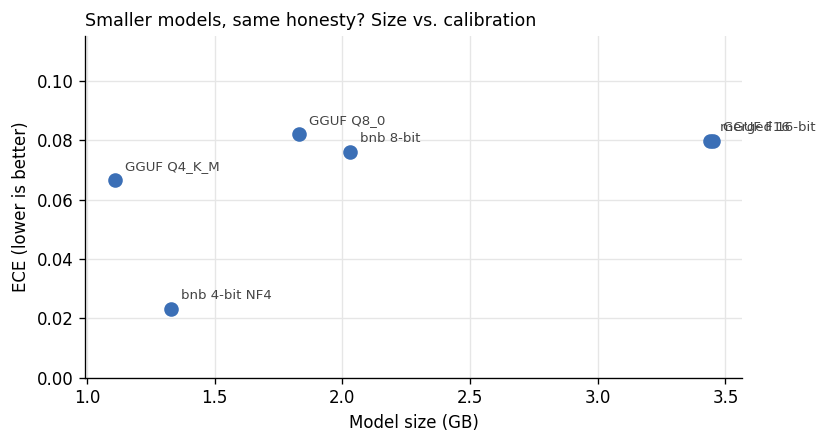

In [18]:
plot = res.dropna(subset=["size_gb"])
fig, ax = plt.subplots(figsize=(7, 3.8), dpi=120)
ax.scatter(plot["size_gb"], plot["ece"], s=60, color="#3b6fb6", zorder=3)
for _, r in plot.iterrows():
    ax.annotate(r["version"].replace(" (sanity check)", ""), (r["size_gb"], r["ece"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8, color="#444")
ax.set_xlabel("Model size (GB)"); ax.set_ylabel("ECE (lower is better)")
ax.set_title("Smaller models, same honesty? Size vs. calibration", fontsize=10.5, loc="left")
ax.set_ylim(0, max(0.03, plot["ece"].max() * 1.4))
ax.grid(color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(f"{SAVE_DIR}/quant_size_vs_ece.png"); plt.show()

# Results: speed on the T4 GPU (PyTorch)

Read across the batch sizes: **ms per decision** at batch 1 is latency. **Decisions per second** at batch 32 is throughput.

In [19]:
spd = pd.DataFrame(SPEED)
print(spd.pivot(index="version", columns="batch", values="ms_per_decision").round(1)
      .rename(columns=lambda b: f"ms/decision @ batch {b}").to_string())
print()
print(spd.pivot(index="version", columns="batch", values="decisions_per_s").round(1)
      .rename(columns=lambda b: f"decisions/s @ batch {b}").to_string())

batch          ms/decision @ batch 1  ms/decision @ batch 8  ms/decision @ batch 32
version                                                                            
bnb 4-bit NF4                   97.9                   33.2                    37.1
bnb 8-bit                      223.2                   51.0                    53.5
merged 16-bit                   60.3                   31.7                    38.5

batch          decisions/s @ batch 1  decisions/s @ batch 8  decisions/s @ batch 32
version                                                                            
bnb 4-bit NF4                   10.2                   30.1                    27.0
bnb 8-bit                        4.5                   19.6                    18.7
merged 16-bit                   16.6                   31.5                    26.0


# Step 4: speed on CPU with llama.cpp

This is how the model would run on a laptop or a cheap server with no GPU. `llama-bench` reports two numbers per model:
- **Prompt processing (pp):** tokens per second while *reading* a prompt. This is our task: one pass over a ~300-token prompt per decision.
- **Token generation (tg):** tokens per second while *writing* new tokens. This is chatbot-style work, and what v3's "D 70" replies needed.

Reading is parallel; writing is one token at a time. **pp is usually many times faster than tg.** Q4 is also much faster than F16 here, because on a CPU the bottleneck is moving weights through memory, and smaller weights move faster.

In [20]:
threads = os.cpu_count()
bench = []
for q, path in GGUFS.items():
    r = subprocess.run(["llama.cpp/build/bin/llama-bench", "-m", path, "-p", str(PROMPT_LEN), "-n", "16",
                        "-t", str(threads), "-r", "2", "-o", "csv"], capture_output=True, text=True)
    try:
        pp, tg = parse_llama_bench(r.stdout)
        bench.append({"format": q, "size_gb": os.path.getsize(path) / 1e9, "prompt_tok_per_s": pp,
                      "gen_tok_per_s": tg, "sec_per_decision": PROMPT_LEN / pp})
        print(f"{q}: reads {pp:.0f} tok/s, writes {tg:.1f} tok/s")
    except Exception as e:
        print(f"{q}: llama-bench output not parsed ({e}). Raw output:\n{r.stdout[-800:]}\n{r.stderr[-800:]}")
bench = pd.DataFrame(bench)
print(f"\nCPU threads: {threads} | prompt length used: {PROMPT_LEN} tokens")
print(bench.round(2).to_string(index=False))

F16: reads 28 tok/s, writes 3.4 tok/s
Q8_0: reads 18 tok/s, writes 5.6 tok/s
Q4_K_M: reads 32 tok/s, writes 8.3 tok/s

CPU threads: 2 | prompt length used: 116 tokens
format  size_gb  prompt_tok_per_s  gen_tok_per_s  sec_per_decision
   F16     3.45             27.55           3.43              4.21
  Q8_0     1.83             17.69           5.60              6.56
Q4_K_M     1.11             31.63           8.27              3.67


In [21]:
res.to_csv(f"{SAVE_DIR}/inference_quality.csv", index=False)
spd.to_csv(f"{SAVE_DIR}/inference_speed_gpu.csv", index=False)
bench.to_csv(f"{SAVE_DIR}/inference_speed_cpu.csv", index=False)
print("Saved inference_quality.csv, inference_speed_gpu.csv, inference_speed_cpu.csv, quant_size_vs_ece.png to Drive")

Saved inference_quality.csv, inference_speed_gpu.csv, inference_speed_cpu.csv, quant_size_vs_ece.png to Drive


# How to read the results

**Quality**
- **GGUF F16 should match merged 16-bit** (top match ≈ 1.0). If so, the conversion is trustworthy and the Q8/Q4 rows are meaningful.
- **8-bit versions** (bnb 8-bit, Q8_0) should be nearly identical to 16-bit: top match ~0.99+, tiny KL.
- **4-bit versions** (NF4, Q4_K_M) are where drift appears. The key question: does **ECE** rise with a "yes" in the bootstrap? If not, you can say "4-bit quantization cut the model ~3x in size without measurably hurting calibration." If it does, you've found that quantization makes this model less honest, which is a more interesting result.
- **"v2 as trained" vs. "merged 16-bit"** shows whether the QLoRA merge mismatch matters.

**Speed**
- **GPU:** batch 32 should give many times the throughput of batch 1, at a higher per-request wait. That's the latency/throughput trade-off every serving system (like vLLM) tunes.
- **bnb 8-bit** may be the *slowest* GPU row: smaller memory, extra conversion work.
- **CPU:** prompt reading should be much faster than token writing, and Q4_K_M faster than F16. That's why a one-pass decision model is cheap to run on a CPU, while a chatbot is not.


Dequantize the 4-bit base, then merge

In [22]:
import bitsandbytes as bnb
from bitsandbytes.functional import dequantize_4bit

DQ_DIR = "/content/merged_v2_dequant"
if not os.path.exists(f"{DQ_DIR}/config.json"):
    # 1. Load the base exactly as v2 was trained on it (4-bit NF4)
    nf4_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    base4 = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=nf4_cfg,
                                                 torch_dtype=torch.float16, device_map={"": 0})
    # 2. Expand each 4-bit layer back to 16-bit, keeping its rounding errors: the weights the adapter actually saw
    deq = {name: dequantize_4bit(m.weight.data, m.weight.quant_state).to(torch.float16).cpu()
           for name, m in base4.named_modules() if isinstance(m, bnb.nn.Linear4bit)}
    del base4; free()
    # 3. Put those weights into a normal 16-bit model, then merge the adapter
    base16 = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map={"": 0})
    mods = dict(base16.named_modules())
    for name, W in deq.items():
        mods[name].weight.data.copy_(W.to(mods[name].weight.device))
    del deq
    merged = PeftModel.from_pretrained(base16, f"{SAVE_DIR}/v2_adapter").merge_and_unload()
    merged.save_pretrained(DQ_DIR, safe_serialization=True); tok.save_pretrained(DQ_DIR)
    del merged, base16, mods; free()
size_dq = sum(os.path.getsize(f) for f in glob.glob(f"{DQ_DIR}/*.safetensors")) / 1e9
print(f"Fixed merged model saved: {size_dq:.2f} GB")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fixed merged model saved: 3.44 GB


Evaluate the fixed merge

In [23]:
model = AutoModelForCausalLM.from_pretrained(DQ_DIR, torch_dtype=torch.float16, device_map={"": 0})
record("FIX merged 16-bit (dequantized base)", model, size_dq, timed=False)
del model; free()

model = AutoModelForCausalLM.from_pretrained(DQ_DIR, quantization_config=nf4, device_map={"": 0})
record("FIX bnb 4-bit NF4", model, model.get_memory_footprint() / 1e9, timed=False)
del model; free()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

FIX merged 16-bit (dequantized base): agreement 0.773 | ECE 0.0032 | KL 0.144 | peak GPU memory 8.47 GB


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

FIX bnb 4-bit NF4: agreement 0.307 | ECE 0.4404 | KL 1.604 | peak GPU memory 6.38 GB


GGUF from the fixed model

In [24]:
FIX = {q: f"{GGUF_DIR}/v2fix-{q}.gguf" for q in ["F16", "Q8_0", "Q4_K_M"]}
if not os.path.exists(FIX["F16"]):
    run([sys.executable, "llama.cpp/convert_hf_to_gguf.py", DQ_DIR, "--outfile", FIX["F16"], "--outtype", "f16"])
for q in ["Q8_0", "Q4_K_M"]:
    if not os.path.exists(FIX[q]):
        run(["llama.cpp/build/bin/llama-quantize", FIX["F16"], FIX[q], q])

for q in ["Q8_0", "Q4_K_M"]:
    model = AutoModelForCausalLM.from_pretrained(GGUF_DIR, gguf_file=os.path.basename(FIX[q]),
                                                 torch_dtype=torch.float16).to(DEVICE)
    record(f"FIX GGUF {q}", model, os.path.getsize(FIX[q]) / 1e9, timed=False)
    del model; free()

[transformers] Loading a GGUF checkpoint with its weights packed is fastest in float32, and this one was asked for in torch.float16. The kernels compute in float32, so every matmul will cast its input and its output. Pass `dtype=torch.float32` to avoid it -- the weights stay quantized regardless, so this costs no extra memory.


Converting and de-quantizing GGUF tensors...:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

FIX GGUF Q8_0: agreement 0.777 | ECE 0.0084 | KL 0.144 | peak GPU memory 8.47 GB


[transformers] Loading a GGUF checkpoint with its weights packed is fastest in float32, and this one was asked for in torch.float16. The kernels compute in float32, so every matmul will cast its input and its output. Pass `dtype=torch.float32` to avoid it -- the weights stay quantized regardless, so this costs no extra memory.


Converting and de-quantizing GGUF tensors...:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

FIX GGUF Q4_K_M: agreement 0.688 | ECE 0.0713 | KL 0.236 | peak GPU memory 8.47 GB


Comparing everything against “v2 as trained”

In [25]:
trained = DISTS["v2 as trained (4-bit + adapter)"][0]
res = pd.DataFrame(RESULTS)
res["top_match_vs_trained"] = [drift(trained, DISTS[v][0])[0] for v in res["version"]]
res["kl_vs_trained"] = [drift(trained, DISTS[v][0])[1] for v in res["version"]]
cols = ["version", "size_gb", "agreement", "mean_conf", "expected_acc", "ece", "kl", "brier",
        "top_match_vs_trained", "kl_vs_trained"]
print(res[cols].round(4).to_string(index=False))

s_tr = row_stats(trained, targets)
for v in ["merged 16-bit", "FIX merged 16-bit (dequantized base)", "FIX GGUF Q8_0", "FIX GGUF Q4_K_M"]:
    print(f"\n{v} vs v2 as trained")
    print(paired_bootstrap(s_tr, row_stats(DISTS[v][0], targets), n_boot=1000).round(4).to_string(index=False))
res.to_csv(f"{SAVE_DIR}/inference_quality_with_fix.csv", index=False)

                             version  size_gb  agreement  mean_conf  expected_acc    ece     kl  brier  top_match_vs_trained  kl_vs_trained
     v2 as trained (4-bit + adapter)      NaN     0.7743     0.6250        0.6239 0.0046 0.1435 0.0765                1.0000         0.0000
                       merged 16-bit     3.44     0.7437     0.6907        0.6110 0.0797 0.2064 0.1049                0.8704         0.0684
                           bnb 8-bit     2.03     0.7462     0.6886        0.6126 0.0760 0.2091 0.1060                0.8689         0.0699
                       bnb 4-bit NF4     1.33     0.7648     0.6454        0.6222 0.0232 0.1506 0.0800                0.9309         0.0098
             GGUF F16 (sanity check)     3.45     0.7437     0.6907        0.6110 0.0797 0.2064 0.1049                0.8704         0.0684
                           GGUF Q8_0     1.83     0.7392     0.6916        0.6094 0.0822 0.2087 0.1058                0.8614         0.0701
                    

In [26]:
!cp /content/gguf/v2fix-Q8_0.gguf "/content/drive/MyDrive/mini-jev/"